# Eksplorasi hasil v0.1: denah bangunan Overture

Notebook ini membaca hasil `python src/footprints.py` (folder `output/`) dan merangkumnya.
Jalankan script utama dulu agar file hasil tersedia.

> **Ingat:** angka di sini adalah **luas denah bangunan** dari data Overture, bukan luas atap
> yang bisa dipasangi panel surya. Ini screening awal, bukan desain teknis
> (lihat disclaimer di `README.md`).

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = yaml.safe_load((ROOT / "config.yaml").read_text(encoding="utf-8"))
out = ROOT / cfg["output"]["dir"]

buildings = gpd.read_file(out / cfg["output"]["buildings_geojson"])
summary = pd.read_csv(out / cfg["output"]["summary_csv"])
aoi = gpd.read_file(ROOT / cfg["input"]["aoi"]) if cfg["input"].get("aoi") else None

# analisis luas di CRS metrik (UTM); GeoJSON tersimpan di WGS84
utm = buildings.estimate_utm_crs()
buildings = buildings.to_crs(utm)
print(f"{len(buildings)} bangunan, CRS analisis: {utm.to_string()}")

117 bangunan, CRS analisis: EPSG:32749


## 1. Ringkasan

In [2]:
summary.T.rename(columns={0: 'nilai'})

,nilai
jumlah_bangunan,117.00
total_luas_m2,56329.60
luas_min_m2,12.71
luas_median_m2,76.32
luas_max_m2,4758.18


## 2. Sebaran luas bangunan

Sebagian besar bangunan berukuran kecil, sedikit yang sangat besar, sehingga sumbu X dibuat logaritmik.

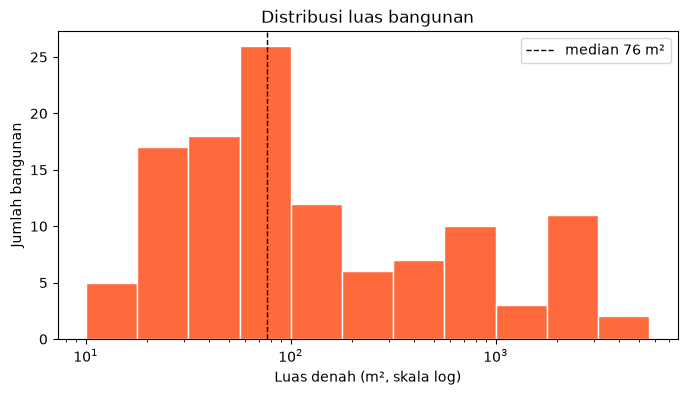

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = [10 ** x for x in [i / 4 for i in range(4, 16)]]
ax.hist(buildings["area_m2"], bins=bins, color="#ff6a3d", edgecolor="white")
ax.axvline(buildings["area_m2"].median(), color="k", ls="--", lw=1,
           label=f"median {buildings['area_m2'].median():.0f} m²")
ax.set_xscale("log")
ax.set_xlabel("Luas denah (m², skala log)")
ax.set_ylabel("Jumlah bangunan")
ax.set_title("Distribusi luas bangunan")
ax.legend()
plt.show()

## 3. Kelas ukuran

Bangunan besar jumlahnya sedikit, tetapi menyumbang porsi luas yang besar.
Untuk screening surya, di sinilah potensi terkonsentrasi.

In [4]:
classes = pd.cut(
    buildings["area_m2"],
    bins=[0, 50, 200, 1000, float("inf")],
    labels=["< 50 m²", "50–200 m²", "200–1.000 m²", "> 1.000 m²"],
)
by_class = buildings.groupby(classes, observed=True)["area_m2"].agg(jumlah="count", total_m2="sum")
by_class["% jumlah"] = (100 * by_class["jumlah"] / by_class["jumlah"].sum()).round(1)
by_class["% luas"] = (100 * by_class["total_m2"] / by_class["total_m2"].sum()).round(1)
by_class["total_m2"] = by_class["total_m2"].round(0)
by_class

,jumlah,total_m2,% jumlah,% luas
area_m2,,,,
< 50 m²,39,1165.0,33.3,2.1
50–200 m²,41,3854.0,35.0,6.8
200–1.000 m²,21,11934.0,17.9,21.2
> 1.000 m²,16,39378.0,13.7,69.9


## 4. Sepuluh bangunan terbesar

In [5]:
top = buildings.nlargest(10, "area_m2")[["id", "area_m2", "is_edge"]].reset_index(drop=True)
top.index += 1
top

,id,area_m2,is_edge
1,5afd4b09-64fc-44bf-b81a-675cff04a412,4758.18,False
2,51c85136-bf0b-4018-a46d-5c1345a2c821,4200.08,False
3,b8c1de66-9e37-4a21-b95e-8b6fce18e97f,2765.03,False
4,bb07ab4d-112b-4bd9-ba95-170429ba0e9b,2711.20,False
5,980701ae-a413-41c2-853f-791d5ff76210,2599.80,False
6,8c26a985-03ab-4030-ac07-af997cf40d22,2590.47,False
7,b09c3ef3-9792-4a9c-b07a-dbbd4b2e5c38,2458.42,False
8,e68d478e-ba65-438a-a08c-c25bfb7eb163,2396.40,False
9,07c1ef02-c0dd-4e4f-8698-01f82976f7b0,2219.27,False
10,096c0952-7441-4b9c-97f5-39d9cd265a2c,2155.03,False


## 5. Peta denah per kelas luas

Peta statis. Untuk peta interaktif di atas ortofoto, buka `output/map.html`.

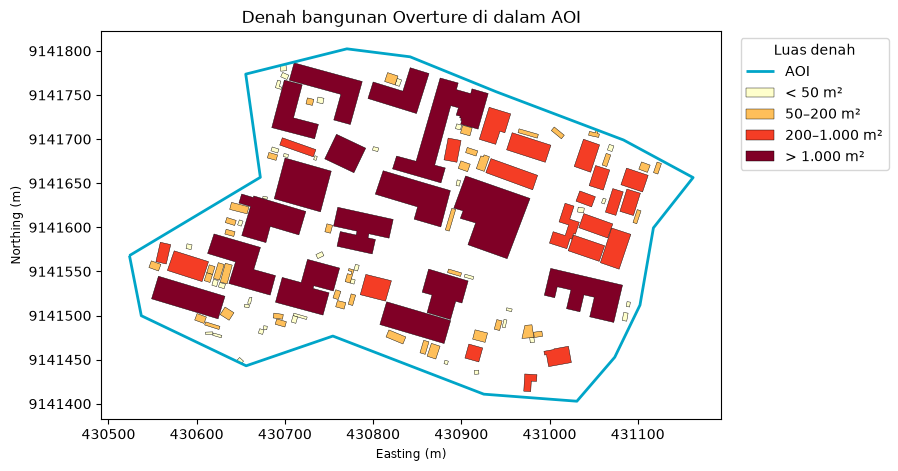

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
if aoi is not None:
    aoi.to_crs(utm).boundary.plot(ax=ax, color="#00a5c8", lw=2, label="AOI")
buildings.plot(ax=ax, column=classes, cmap="YlOrRd", legend=True, edgecolor="k", linewidth=0.3,
               legend_kwds={"title": "Luas denah", "loc": "upper left", "bbox_to_anchor": (1.02, 1)})
ax.ticklabel_format(style="plain", useOffset=False)
ax.set_title("Denah bangunan Overture di dalam AOI")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
plt.show()

## 6. Catatan kualitas data

In [7]:
n_edge = int(buildings["is_edge"].sum())
print(f"Bangunan terpotong tepi AOI : {n_edge} dari {len(buildings)} "
      f"({100 * n_edge / len(buildings):.1f}%) - luasnya hanya sebagian dari bangunan sebenarnya")
if "height" in buildings:
    print(f"Bangunan dengan atribut tinggi: {buildings['height'].notna().sum()} dari {len(buildings)}")
if "num_floors" in buildings:
    print(f"Bangunan dengan atribut jumlah lantai: {buildings['num_floors'].notna().sum()} dari {len(buildings)}")

Bangunan terpotong tepi AOI : 3 dari 117 (2.6%) - luasnya hanya sebagian dari bangunan sebenarnya
Bangunan dengan atribut tinggi: 0 dari 117
Bangunan dengan atribut jumlah lantai: 31 dari 117


## 7. Estimasi energi (v0.2)

Tiga skenario (rendah / dasar / tinggi) dengan asumsi dari literatur Indonesia, lihat bagian
*Referensi* di `README.md`. Nilainya diatur di `config.yaml` (bagian `solar`).

> **Ingat:** ini screening berbasis luas. Kemiringan, arah, dan bayangan atap tidak dimodelkan.

In [8]:
import sys

sys.path.insert(0, str(ROOT / "src"))
import solar

scen = pd.read_csv(out / cfg["output"]["scenarios_csv"]).set_index("skenario")
scen[["faktor_pemanfaatan", "efisiensi_modul", "performance_ratio",
      "luas_efektif_m2", "kapasitas_kwp", "energi_mwh_tahun", "yield_kwh_per_kwp"]]

,faktor_pemanfaatan,efisiensi_modul,performance_ratio,luas_efektif_m2,kapasitas_kwp,energi_mwh_tahun,yield_kwh_per_kwp
skenario,,,,,,,
low,0.125,0.173,0.70,7041.2,1218.1,1635.5,1343.0
base,0.490,0.200,0.75,27601.5,5520.3,7941.0,1438.0
high,0.640,0.228,0.80,36050.9,8219.6,12612.2,1534.0


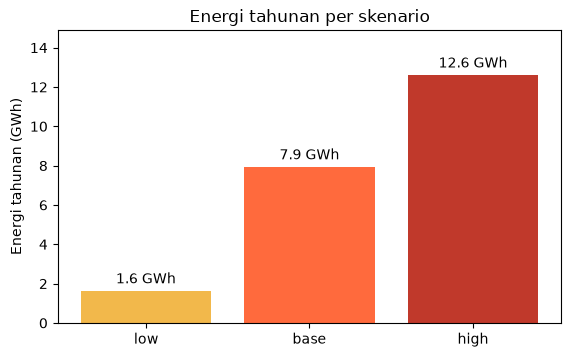

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
colors = {"low": "#f2b84b", "base": "#ff6a3d", "high": "#c0392b"}
bars = ax.bar(scen.index, scen["energi_mwh_tahun"] / 1000, color=[colors[s] for s in scen.index])
ax.bar_label(bars, fmt="%.1f GWh", padding=3)
ax.set_ylabel("Energi tahunan (GWh)")
ax.set_title("Energi tahunan per skenario")
ax.set_ylim(0, scen["energi_mwh_tahun"].max() / 1000 * 1.18)
plt.show()

## 8. Parameter mana yang paling menentukan?

Satu parameter diubah dari nilai dasar ke nilai rendah/tinggi, yang lain tetap (analisis sensitivitas
*one-at-a-time*). Panjang batang menunjukkan seberapa besar parameter itu menggeser hasil.

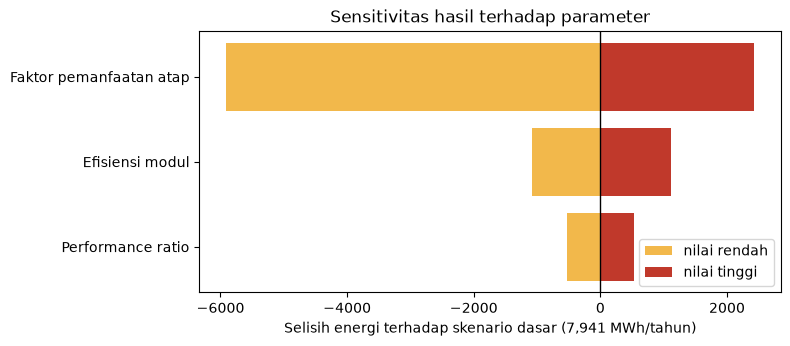

,turun,naik
parameter,,
Performance ratio,-529.0,529.0
Efisiensi modul,-1072.0,1112.0
Faktor pemanfaatan atap,-5915.0,2431.0


In [10]:
scs = {s.name: s for s in solar.scenarios_from_config(cfg["solar"])}
ghi = cfg["solar"]["annual_ghi_kwh_m2"]
base = scs[cfg["solar"]["base_scenario"]]
area = buildings["area_m2"]
total = lambda sc: solar.annual_energy_kwh(area, sc, ghi).sum() / 1000  # MWh/tahun
e_base = total(base)

from dataclasses import replace
params = {"utilization_factor": "Faktor pemanfaatan atap",
          "module_efficiency": "Efisiensi modul",
          "performance_ratio": "Performance ratio"}
rows = []
for key, label in params.items():
    lo = total(replace(base, **{key: getattr(scs["low"], key)}))
    hi = total(replace(base, **{key: getattr(scs["high"], key)}))
    rows.append((label, lo - e_base, hi - e_base))
sens = pd.DataFrame(rows, columns=["parameter", "turun", "naik"]).set_index("parameter")
sens["rentang"] = sens["naik"] - sens["turun"]
sens = sens.sort_values("rentang")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(sens.index, sens["turun"], color="#f2b84b", label="nilai rendah")
ax.barh(sens.index, sens["naik"], color="#c0392b", label="nilai tinggi")
ax.axvline(0, color="k", lw=1)
ax.set_xlabel(f"Selisih energi terhadap skenario dasar ({e_base:,.0f} MWh/tahun)")
ax.set_title("Sensitivitas hasil terhadap parameter")
ax.legend(loc="lower right")
plt.show()
sens[["turun", "naik"]].round(0)

**Cara membaca:** faktor pemanfaatan atap adalah ketidakpastian terbesar, karena nilainya di literatur
bergantung pada jenis atap (miring atau datar), bayangan, dan peralatan di atap. Efisiensi modul dan
performance ratio punya pengaruh jauh lebih kecil. Mengurangi ketidakpastian faktor pemanfaatan
(misalnya dengan deteksi atap sendiri, v0.3) lebih bernilai daripada memperhalus parameter lain.

## Langkah berikutnya

- **v0.3:** bandingkan denah Overture dengan atap hasil deteksi SAM dari ortofoto.
- **v0.4:** analisis kemiringan dan arah atap jika DSM tersedia.